In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/Bhumika Chandan/Downloads/Dataset .csv")

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (9551, 21)


,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [4]:
print("Minimum Rating:", df["Aggregate rating"].min())
print("Maximum Rating:", df["Aggregate rating"].max())

print("\nRating Values:")
print(df["Aggregate rating"].value_counts().sort_index())

Minimum Rating: 0.0
Maximum Rating: 4.9

Rating Values:
Aggregate rating
0.0    2148
1.8       1
1.9       2
2.0       7
2.1      15
2.2      27
2.3      47
2.4      87
2.5     110
2.6     191
2.7     250
2.8     315
2.9     381
3.0     468
3.1     519
3.2     522
3.3     483
3.4     498
3.5     480
3.6     458
3.7     427
3.8     400
3.9     335
4.0     266
4.1     274
4.2     221
4.3     174
4.4     144
4.5      95
4.6      78
4.7      42
4.8      25
4.9      61
Name: count, dtype: int64


In [5]:
bins = [0, 1, 2, 3, 4, 5]

labels = [
    "0-1 Poor",
    "1-2 Average",
    "2-3 Good",
    "3-4 Very Good",
    "4-5 Excellent"
]

df["Rating Range"] = pd.cut(
    df["Aggregate rating"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

rating_distribution = df["Rating Range"].value_counts().sort_index()

display(rating_distribution)

Rating Range
0-1 Poor         2148
1-2 Average        10
2-3 Good         1891
3-4 Very Good    4388
4-5 Excellent    1114
Name: count, dtype: int64

In [6]:
most_common_range = rating_distribution.idxmax()

most_common_count = rating_distribution.max()

print("Most Common Rating Range:", most_common_range)
print("Number of Restaurants:", most_common_count)

Most Common Rating Range: 3-4 Very Good
Number of Restaurants: 4388


In [7]:
average_votes = df["Votes"].mean()

print("Average Votes per Restaurant:", round(average_votes, 2))

Average Votes per Restaurant: 156.91


In [8]:
print("Most Common Rating Range:", most_common_range)
print("Number of Restaurants:", most_common_count)

Most Common Rating Range: 3-4 Very Good
Number of Restaurants: 4388


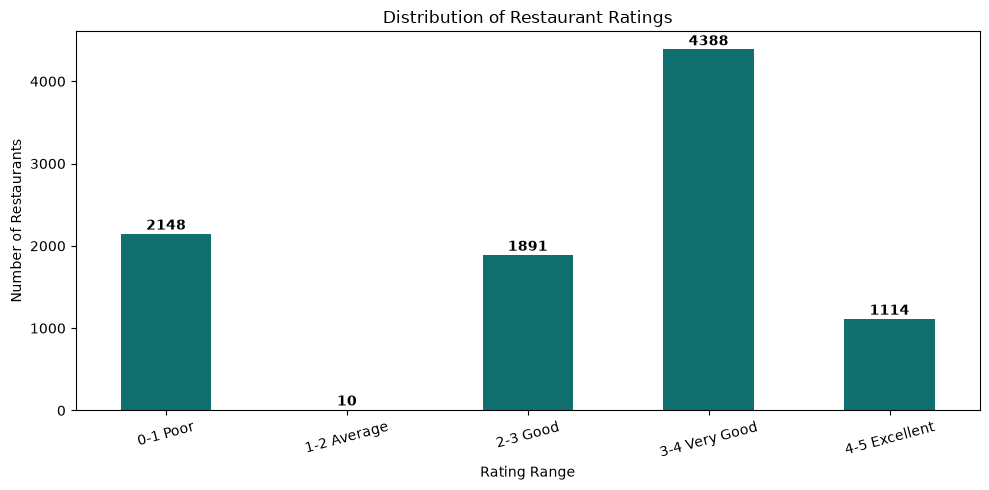

In [9]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=rating_distribution.index,
    y=rating_distribution.values,
    color="teal",
    width=0.5
)

# Add count labels
for i, value in enumerate(rating_distribution.values):
    ax.text(
        i, value + 50,
        str(value),
        ha="center",
        fontweight="bold"
    )

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Rating Range")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("Restaurant_Rating_Distribution.png", dpi=300)
plt.show()

In [10]:
rating_result = pd.DataFrame({
    "Rating Range": rating_distribution.index.astype(str),
    "Restaurant Count": rating_distribution.values
})

rating_result.to_csv("Restaurant_Rating_Analysis.csv", index=False)

print("Restaurant Ratings Task Completed Successfully!")

Restaurant Ratings Task Completed Successfully!
